# 📡 07 · Monitoring: data drift
### Monitoreo: deriva de datos (data drift)

| | |
|---|---|
| 🍳 **Analogy / Analogía** | *Are customers still ordering the same dishes?* · *¿Los clientes siguen pidiendo lo mismo?* |
| 🎯 **Goal / Objetivo** | Detect when today's market no longer looks like the training market · Detectar cuándo el mercado de hoy ya no se parece al de entrenamiento |
| 🏭 **Becomes / Se convierte en** | `src/monitoring/drift.py` (last DVC stage) |

```
  deploy ──▶ time passes ──▶ market changes ──▶ 📉 model gets worse silently
                                   ▲
                       📡 drift monitor catches it here → 🔁 retrain (back to step 1)
```

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import ks_2samp

plt.rcParams["figure.figsize"] = (11, 4)
path = "data/processed/features.csv" if Path("data/processed/features.csv").exists() else "data/processed/features_sample.csv"
df = pd.read_csv(path, parse_dates=["time"])
cut = int(len(df) * 0.8)
reference, current = df.iloc[:cut], df.iloc[-500:]
print(f"Reference (training): {reference.time.min():%Y-%m-%d} → {reference.time.max():%Y-%m-%d}")
print(f"Current  (recent)   : {current.time.min():%Y-%m-%d} → {current.time.max():%Y-%m-%d}")

Reference (training): 2021-09-13 → 2025-09-24
Current  (recent)   : 2026-08-28 → 2026-09-29


## 1️⃣ See it: gold's volatility over time / Verlo: la volatilidad del oro en el tiempo

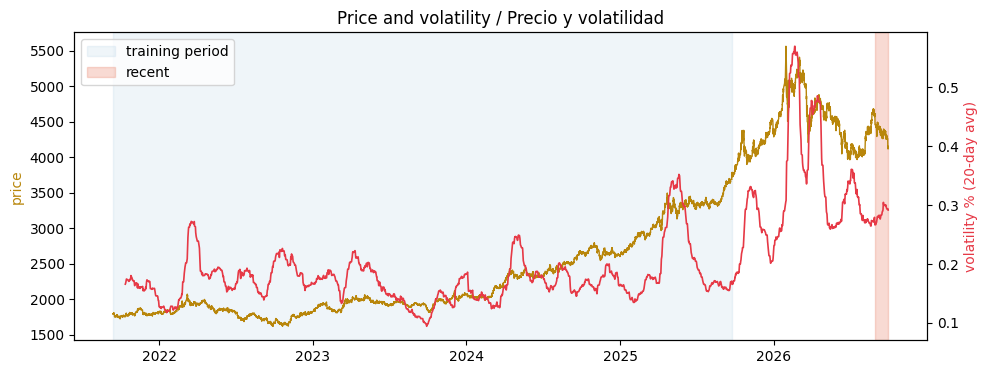

In [2]:
fig, ax1 = plt.subplots()
ax1.plot(df.time, df.close, color="#b8860b", lw=1)
ax1.set_ylabel("price", color="#b8860b")
ax2 = ax1.twinx()
ax2.plot(df.time, df.volatility.rolling(24 * 20).mean() * 100, color="#e63946", lw=1.2)
ax2.set_ylabel("volatility % (20-day avg)", color="#e63946")
ax1.axvspan(reference.time.min(), reference.time.max(), color="#1f77b4", alpha=0.07, label="training period")
ax1.axvspan(current.time.min(), current.time.max(), color="#e76f51", alpha=0.25, label="recent")
ax1.legend(loc="upper left")
ax1.set_title("Price and volatility / Precio y volatilidad")
plt.show()

## 2️⃣ Measure it: the KS test / Medirlo: la prueba KS
**EN:** Kolmogorov–Smirnov compares two histograms and gives a number from 0 (identical) to 1 (totally different).
**ES:** Kolmogorov–Smirnov compara dos histogramas y da un número de 0 (idénticos) a 1 (totalmente distintos).

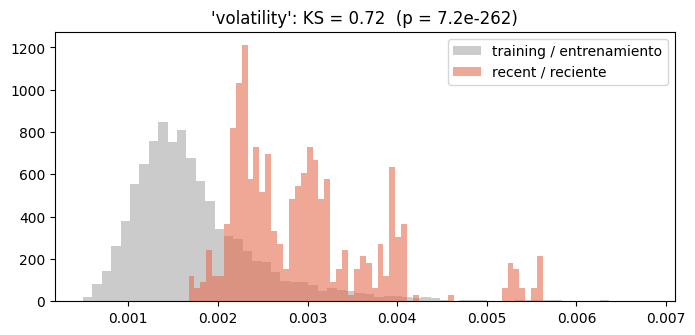

In [3]:
feature = "volatility"
stat, p = ks_2samp(reference[feature], current[feature])
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(reference[feature], bins=60, density=True, alpha=0.5, color="#999", label="training / entrenamiento")
ax.hist(current[feature], bins=60, density=True, alpha=0.6, color="#e76f51", label="recent / reciente")
ax.set_title(f"'{feature}': KS = {stat:.2f}  (p = {p:.1e})")
ax.legend()
plt.show()

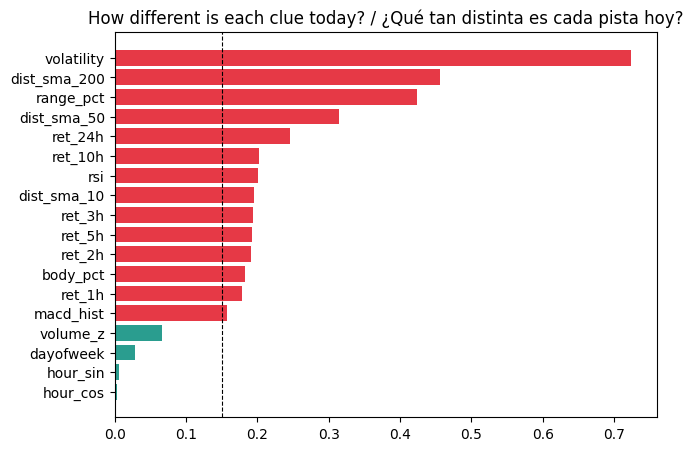

In [4]:
features = [c for c in df.columns if c not in ("time", "close", "target")]
drift = pd.DataFrame([{"feature": f, "KS": ks_2samp(reference[f], current[f])[0]} for f in features]) \
    .sort_values("KS", ascending=True)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(drift.feature, drift.KS, color=["#e63946" if v > 0.15 else "#2a9d8f" for v in drift.KS])
ax.axvline(0.15, color="black", ls="--", lw=0.8)
ax.set_title("How different is each clue today? / ¿Qué tan distinta es cada pista hoy?")
plt.show()

**EN — What does it mean?** Gold is now far more volatile than during most of the training years
(the big rally). The clues that depend on the *size* of moves drifted; calendar clues (hour/day) didn't.
➡️ **Action:** retrain with recent data: `dvc repro -f extract` → the whole pipeline runs again → new champion
only if it passes the gate.

**ES — ¿Qué significa?** El oro hoy es mucho más volátil que en la mayoría de los años de entrenamiento
(el gran rally). Las pistas que dependen del *tamaño* de los movimientos derivaron; las del calendario no.
➡️ **Acción:** reentrenar con datos recientes: `dvc repro -f extract` → todo el pipeline corre de nuevo → nuevo
campeón solo si pasa el control de calidad.

---
## 🔁 From notebook to production / Del notebook a producción

| Notebook | Production (`src/monitoring/drift.py`) |
|---|---|
| One feature at a time | Every feature, KS + p-value, sorted |
| We read the chart | `reports/drift.json` with `retrain_recommended: true/false` |
| Manual | Last DVC stage → runs with every `dvc repro`; also in the CI smoke test |
| — | 💡 Next level: schedule it (cron / GitHub Actions `schedule:`) and alert on Slack/email |